## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Patrick Lee 

**Date:** 10/12/2026

In [11]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

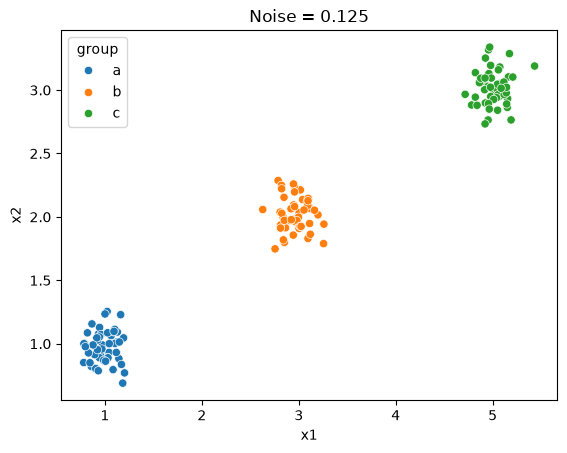

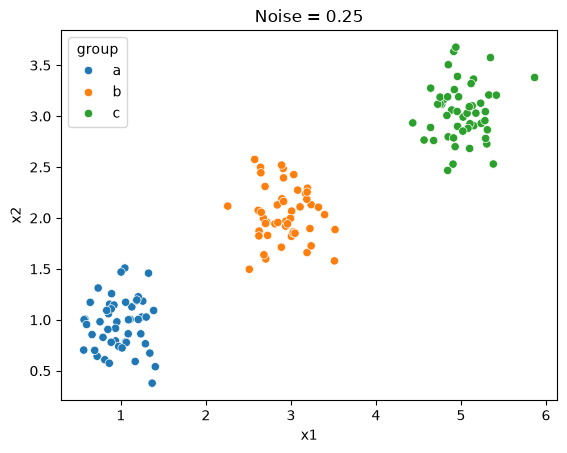

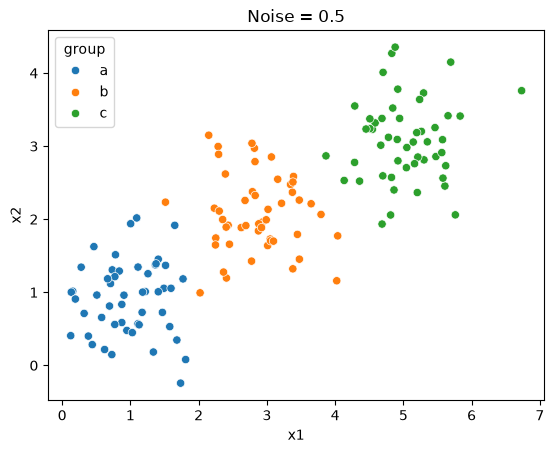

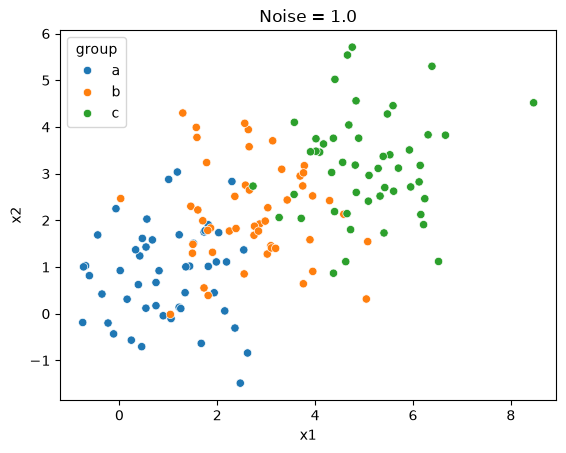

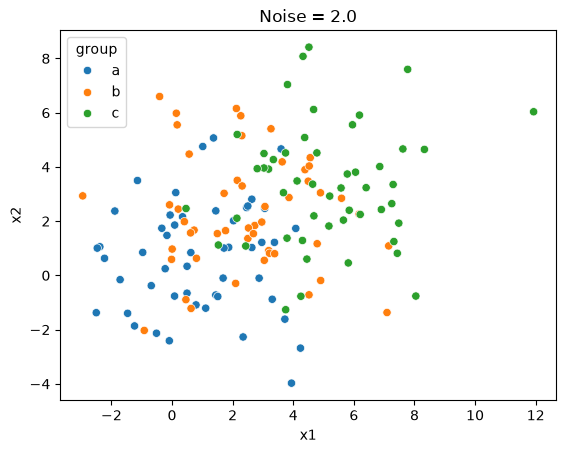

In [ ]:
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for i in range(5):
    sns.scatterplot(data=datasets[i], x="x1", y="x2", hue="group")
    plt.title("Noise = " + str(noises[i]))
    plt.show()

# As the noise increases, the groups spread out and overlap more
# The three groups are clearly separated at 0.125 and 0.25 but at 1.0 and 2.0 it becomes much harder to tell the groups apart

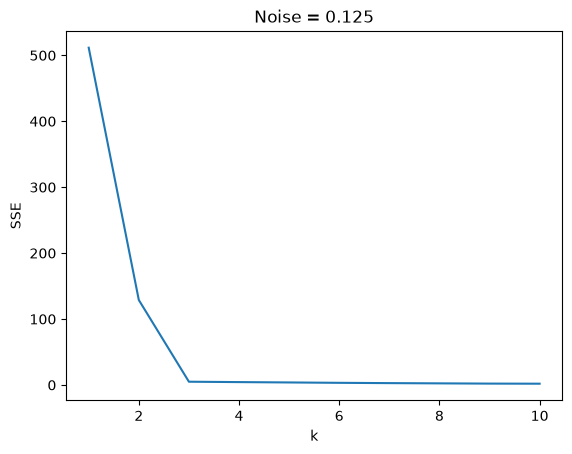

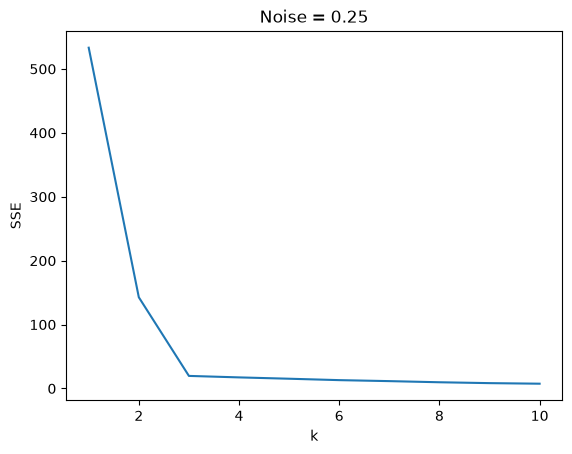

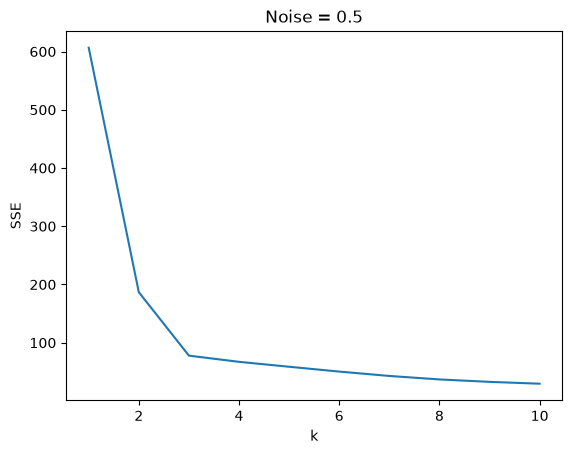

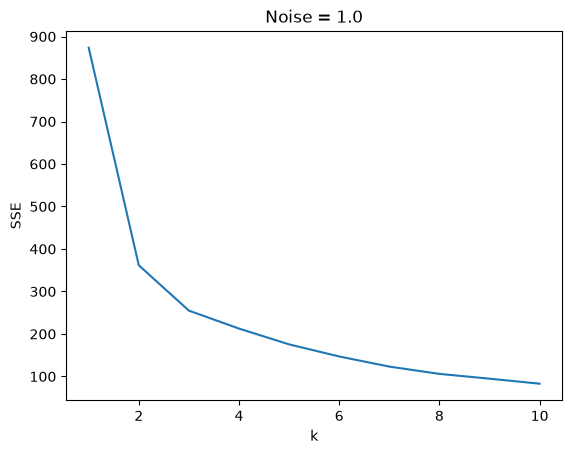

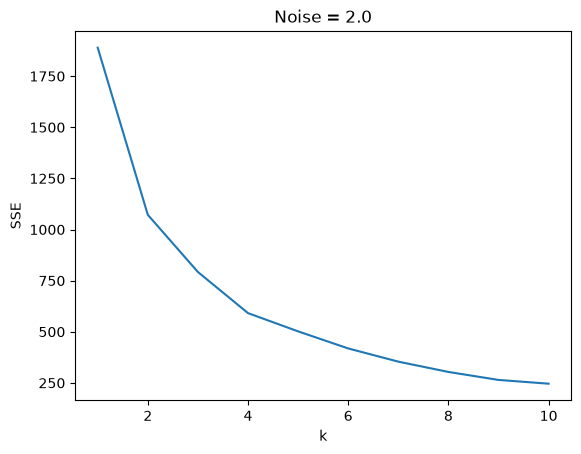

In [ ]:
ks = np.arange(1, 11)

for i in range(5):
    X = datasets[i].loc[:, ["x1", "x2"]]

    SSE = [
        KMeans(n_clusters=k, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

    sns.lineplot(x=ks, y=SSE).set(title="Noise = " + str(noises[i]), xlabel="k", ylabel="SSE")
    plt.show()
# At lower noise levels, there is a clear elbow at k = 3. Adding more clusters only reduces SSE a little 
# As noise increases, SSE gets larger and the elbow becomes less clear which makes it harder to choose k

# Q1 part 4
# The elbow happens when adding another cluster stops reducing SSE by a big amount
# Three clusters work well when the noise is low since there are three distinct groups, adding more mostly splits those groups into smaller ones
# With more noise, the groups overlap making it harder to see the elbow

In [ ]:
df = pd.read_csv("data/SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020].dropna().copy()

print(df.shape)
print(df.dtypes)
# There are 148 countries after filtering to 2020 and dropping missing values
# The four spending variables are already numeric so conversion isn't needed


(148, 7)
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


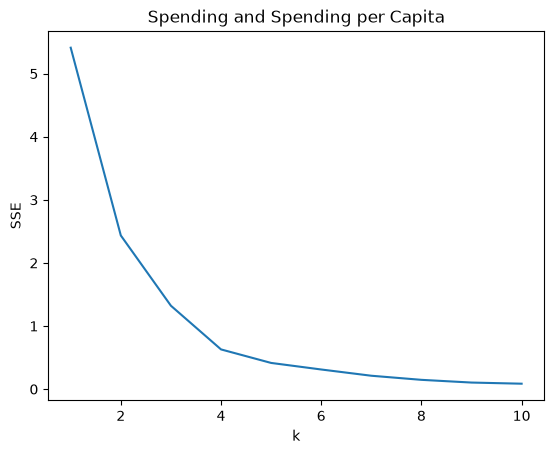

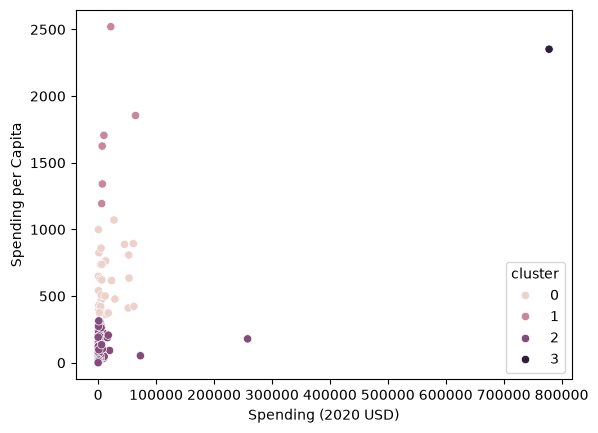

cluster
2    111
0     30
1      6
3      1
Name: count, dtype: int64
        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032

In [ ]:
features = ["Spending (2020 USD)", "Spending per Capita"]

unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Spending and Spending per Capita",
    xlabel="k", ylabel="SSE"
)
plt.show()

model = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster"
)
plt.show()

print(df["cluster"].value_counts())
print(df.groupby("cluster")[features].describe())

print(df[df["Country"] == "United States of America"])
# I chose k = 4 since the scree plot starts to flatten after four clusters
# cluster 2 has 111 countries with lower spending per capita, cluster 0 has 30 with moderate spending per capita, and cluster 1 has six with high spending per capita
# The United States is alone in cluster 3 since its total spending is much higher than the other countries.

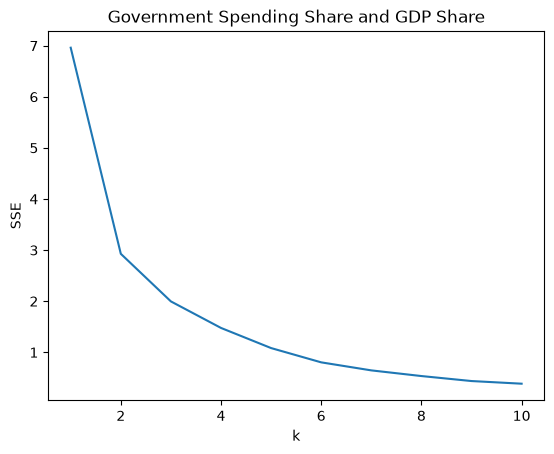

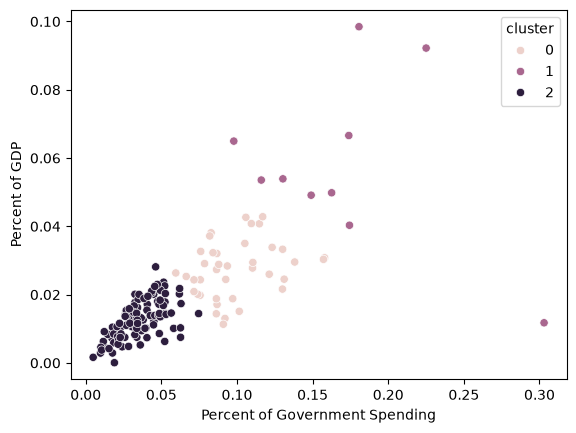

cluster
2    99
0    39
1    10
Name: count, dtype: int64
        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                    

In [ ]:
features = ["Percent of Government Spending", "Percent of GDP"]

unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [
    KMeans(n_clusters=k, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Government Spending Share and GDP Share",
    xlabel="k", ylabel="SSE"
)
plt.show()

model = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

sns.scatterplot(
    data=df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster"
)
plt.show()

print(df["cluster"].value_counts())
print(df.groupby("cluster")[features].describe())

print(df[df["Country"] == "United States of America"])
# I chose k = 3, the clusters roughly separate countries with low, medium, and high military spending shares
# The United States is in cluster 0 instead of being alone
# This result differs from part 2 since these variables measure spending relative to the government budget and GDP, so having high total spending does not necessarily put a country in the highest group

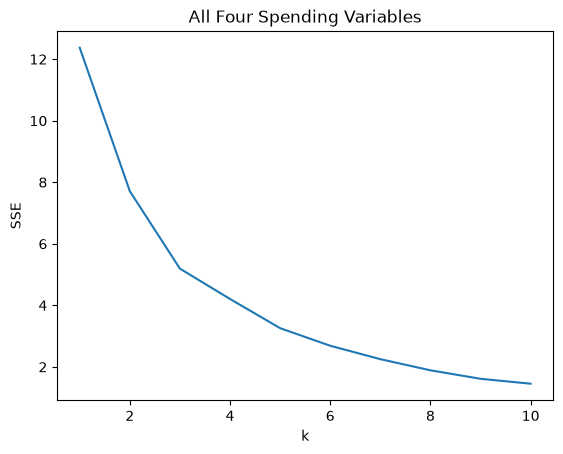

cluster
0    111
1     31
2      6
Name: count, dtype: int64
        Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
           

In [ ]:
features = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [
    KMeans(n_clusters=k, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="All Four Spending Variables",
    xlabel="k", ylabel="SSE"
)
plt.show()

model = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

print(df["cluster"].value_counts())
print(df.groupby("cluster")[features].describe())

print(df[df["Country"] == "United States of America"])
# I chose k = 3 since the SSE reductions become smaller after three clusters
# Cluster 0 has 111 countries with generally lower spending shares and spending per capita, cluster 1 has 31 countries with higher spending shares, cluster 2 has six countries with high spending per capita, including the United States
# Using all four variables changes the groups because the model considers both the amount spent and the spending shares

# Q2 part 5
# I think the clusters show useful differences in military spending since the first model groups countries by total spending and spending per person and the second groups them by the share of their budget and GDP spent on the military
# Using all four variables combines these patterns. The groups depend on the variables and k chosen but don't explain why countries spend differently

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 9e057120cfe002226ba1dbe482c139d4a96fd1ec
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. "I'm doing Phase 2 for A04. Look at my Phase 1 notebook (A04-knn/notebook.ipynb) and suggest revisions and improvements based on the assignment requirements."
2. "Give me the proposed changes as a concise numbered list, and give me the revised Phase 2 code so I can paste it in myself. Don't touch the frozen Phase 1 cells."

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Put all five Q1 scree curves on one canvas with a shared vertical axis, as the assignment asks. The separate plots have different y-scales, so the effect of noise on the elbow can't be compared.
2. Quantify the elbow in Q1.3 instead of saying "lower noise levels". Report the percent SSE drop from k=2 to k=3 versus k=3 to k=4 for each noise level, so it is clear where the elbow disappears.
3. Q2.1 asks whether more cleaning is needed, and Phase 1 only assumed the answer. Check for duplicate countries and zero or negative values before saying no further cleaning is needed.
4. Q2.2 asks about patterns in cluster membership, but Phase 1 only says where the United States is. Describe which kinds of countries land in each cluster.
5. The scree plots for Q2.3 and Q2.4 have no sharp elbow, so k=3 is not well supported. Add the silhouette score as a second criterion for choosing k in Q2.2 through Q2.4.
6. Standardize with z-scores instead of max-min normalization.



### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Combined scree plot | Accept | The assignment says to put the curves on one canvas or watch the vertical axis. SSE at k=1 grows with noise, which separate plots hide. |
| 2. Quantify the elbow | Accept | My Phase 1 comment was vague since the SSE drop from k=2 to k=3 is 96%, 86%, 58%, 30% and 26% across the five noise levels, while the drop from k=3 to k=4 stays between 12% and 25%. So the elbow is still clear at noise 0.5, weak at 1.0 and gone at 2.0. |
| 3. Check duplicates and nonpositive values | Accept | Phase 1 only assumed no cleaning was needed. Checking shows no duplicate countries and no zero or negative values, so the answer is still no further cleaning. |
| 4. Describe cluster membership | Accept | The assignment asks about patterns in membership, and my Phase 1 only located the US. I checked the countries in each cluster against the output. |
| 5. Silhouette score for choosing k | Modify | I added it as a check but kept my Phase 1 k. Silhouette is highest at k=2 for all three sets of variables, which mostly splits off the extreme countries from everyone else and is less informative. |
| 6. z-score instead of max-min | Reject | The assignment specifically says to max-min normalize, and keeping the same scaling in all three parts makes the results comparable. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

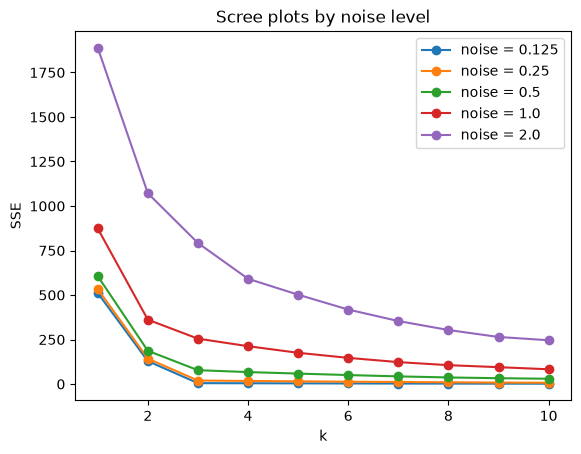

noise 0.125 | drop k=2->3: 96% | drop k=3->4: 12%
noise 0.25 | drop k=2->3: 86% | drop k=3->4: 12%
noise 0.5 | drop k=2->3: 58% | drop k=3->4: 14%
noise 1.0 | drop k=2->3: 30% | drop k=3->4: 17%
noise 2.0 | drop k=2->3: 26% | drop k=3->4: 25%
Duplicate countries: 0
Values <= 0:
 Spending (2020 USD)               0
Spending per Capita               0
Percent of Government Spending    0
Percent of GDP                    0
dtype: int64
Cluster 0 ( 30 countries ): Australia, Austria, Bahrain, Belgium, Brunei, Canada, Cyprus, Denmark, Estonia, Finland
Cluster 1 ( 6 countries ): Israel, Kuwait, Norway, Oman, Saudi Arabia, Singapore
Cluster 2 ( 111 countries ): Afghanistan, Albania, Algeria, Angola, Argentina, Armenia, Azerbaijan, Bangladesh, Belarus, Belize
Cluster 3 ( 1 countries ): United States of America
Spending + per capita {2: 0.759, 3: 0.743, 4: 0.701, 5: 0.649, 6: 0.654, 7: 0.653, 8: 0.6}
Gov share + GDP share {2: 0.616, 3: 0.539, 4: 0.451, 5: 0.459, 6: 0.417, 7: 0.383, 8: 0.376}
Al

In [25]:
# Your Phase 2 solution to the problem goes here.
from sklearn.metrics import silhouette_score

# suggestion 1: all five scree curves on one canvas, shared vertical axis
ks = np.arange(1, 11)
for i in range(5):
    X = datasets[i].loc[:, ["x1", "x2"]]
    SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    plt.plot(ks, SSE, marker="o", label="noise = " + str(noises[i]))
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Scree plots by noise level")
plt.legend()
plt.show()

# suggestion 2: quantify the elbow (percent SSE drop going from k-1 to k)
for i in range(5):
    X = datasets[i].loc[:, ["x1", "x2"]]
    SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in range(1, 5)]
    print("noise", noises[i],
          "| drop k=2->3: {:.0%}".format(1 - SSE[2] / SSE[1]),
          "| drop k=3->4: {:.0%}".format(1 - SSE[3] / SSE[2]))

# suggestion 3: check the SIPRI data instead of assuming it is clean
numeric_cols = ["Spending (2020 USD)", "Spending per Capita",
                "Percent of Government Spending", "Percent of GDP"]
print("Duplicate countries:", df["Country"].duplicated().sum())
print("Values <= 0:\n", (df[numeric_cols] <= 0).sum())

# suggestion 4: which countries are in each cluster (part 2 clusters)
unscaled = df.loc[:, ["Spending (2020 USD)", "Spending per Capita"]]
X = (unscaled - unscaled.min()) / (unscaled.max() - unscaled.min())
df["cluster_p2"] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_
for c, group in df.groupby("cluster_p2"):
    print("Cluster", c, "(", len(group), "countries ):", ", ".join(group["Country"].head(10)))

# suggestion 5: silhouette score as a second criterion for k
variable_sets = {
    "Spending + per capita": ["Spending (2020 USD)", "Spending per Capita"],
    "Gov share + GDP share": ["Percent of Government Spending", "Percent of GDP"],
    "All four": numeric_cols,
}
for name, cols in variable_sets.items():
    unscaled = df.loc[:, cols]
    X = (unscaled - unscaled.min()) / (unscaled.max() - unscaled.min())
    scores = {k: round(silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)), 3)
              for k in range(2, 9)}
    print(name, scores)


### Written answers (Phase 2)

**Q1.2 – Scatterplots.** At noise 0.125 and 0.25 the three groups are tight and clearly separated. At 0.5 they still look distinct but their edges start to touch. At 1.0 and 2.0 the groups overlap heavily and the colors are mixed, so the clusters can't be told apart by eye.

**Q1.3 – Scree plots.** On a shared vertical axis, SSE at k = 1 grows with noise because the points are more spread out. The drop in SSE from k = 2 to k = 3 is 96%, 86%, 58%, 30% and 26% for noise 0.125, 0.25, 0.5, 1.0 and 2.0, while the drop from k = 3 to k = 4 is only 12% to 25%. So the elbow at k = 3 is very clear at the two lowest noise levels, still clear at 0.5, weak at 1.0, and gone at 2.0, where both drops are about the same. As noise rises I can no longer select k definitively from the scree plot.

**Q1.4 – Intuition of the elbow.** SSE always falls as k increases because every point gets closer to a center. The elbow is where an extra cluster stops buying a large drop. With three true groups, the third cluster removes a lot of error, but a fourth only splits a group that was already compact. When noise is high the groups overlap, so each extra cluster reduces error by a similar amount and there is no natural stopping point.

**Q2.1 – Cleaning.** After filtering to 2020 and dropping missing values there are 148 countries. All four spending variables are already numeric, there are no duplicate countries, and no values are zero or negative, so no further cleaning is required.

**Q2.2 – Spending and spending per capita (k = 4).** The scree plot's SSE drops by about half going to k = 4 and by only about a third after that, so k = 4 is reasonable. The clusters are 111 countries with low spending and low spending per capita, 30 wealthy countries with moderate per capita spending (for example Australia, Austria, Belgium, Canada and Denmark), 6 with high spending per capita (Israel, Kuwait, Norway, Oman, Saudi Arabia and Singapore), and the United States alone. The US is its own cluster because its total spending ($778B) is far above every other country's. The high per capita cluster is not made of the largest spenders but of small or wealthy countries that spend a lot per person. Silhouette is highest at k = 2 (0.76 versus 0.70 at k = 4), but k = 2 mostly separates the extreme countries from everyone else, so I kept k = 4.

**Q2.3 – Percent of government spending and percent of GDP (k = 3).** The clusters roughly separate low, medium and high military burden: 99 countries average about 3.6% of government spending, 39 about 9.9%, and 10 about 17.1%. The high group includes Algeria, Armenia, Azerbaijan, Belarus, Israel, Jordan, Kuwait and Oman. The US is in the middle cluster rather than alone. This differs from part 2 because these variables measure spending relative to the budget and economy, not in absolute dollars. The scree plot has no sharp elbow (SSE keeps falling by 26% to 32% per step), and silhouette is highest at k = 2 (0.62 versus 0.54 at k = 3), so k = 3 is a judgment call.

**Q2.4 – All four variables (k = 3).** The clusters are 111 countries with low values across the board, 31 with higher spending shares, and 6 with high spending per capita and high shares: Israel, Kuwait, Oman, Saudi Arabia, Singapore and the US. This combines the two earlier results, and the US no longer stands alone because its total spending is only one of four dimensions. Again silhouette is highest at k = 2 (0.58 versus 0.48 at k = 3) and the scree plot has no sharp elbow, so the choice of k is subjective.

**Q2.5 – Usefulness.** The clustering did find useful structure. Total and per capita spending separate the US, then a small set of wealthy high-per-person spenders, from everyone else. Spending shares separate countries by how heavily military spending weighs on their budget. The patterns depend on which variables are used and on k, and the later scree plots have no clear elbow. The clusters describe how countries differ but do not explain why they spend differently.


### *Reflection on AI assistance
In your own words without generative AI.


[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

I think overall the AI was good at giving me suggestions and improvements. I know in the past it has been a little bit too much in trying to find a bunch of things to change but this time it was pretty good about it and gave suggestions that made sense for the most part. Combining the Q1 scree curves on a shared axis made the effect of noise easier to compare and calculating the percentage drops in SSE supported my explanation of why the elbow becomes weaker. The duplicate and nonpositive-value checks was also good changes I think. I do think though that some AI suggestions did not fit the assignment. Replacing min-max normalization with z-scores wouldn't align with what the assignment was asking for so I ended up just rejecting that one. I verfied the solution by running its code improvement and seeing if it matches up and making sure that its output actually makes sense. I then looked at the markdown cell it wrote up and saw if each of its answers made sense which I think they did.